L'objet de ce projet est d'étudier des algorithmes de scoring aidant à la décision d'un accord de prêt. 

La finalité est d'utiliser des historiques de prêts et d'informations financières pour évaluer la probabilité de remboursement du prêt par le candidat. Les utilisateurs du modèle de scoring sont les chargés de relation client. Ils devront être capables de donner une justification concrête pour la non-attribution d'un prêt. 

Le modèle doit donc être facilement interprétable. 

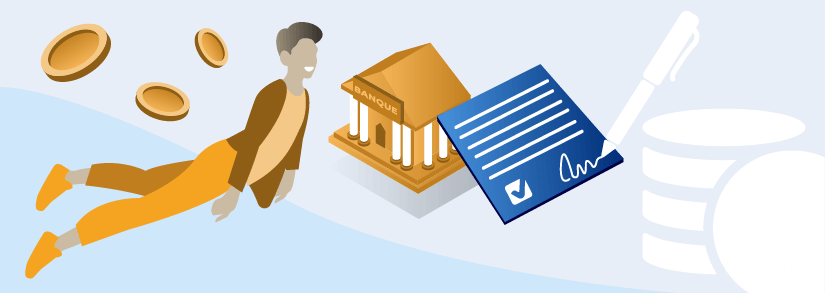

# Préparation, visualisation et exploration des données

## Importation des données et des librairies

### Importation des librairies utiles au projet

In [1]:
# numpy and pandas pour la manipulation des données
import numpy as np
import pandas as pd
# matplotlib and seaborn pour les représentations graphiques
import matplotlib.pyplot as plt
import seaborn as sns

# File system management
import os

# Suppress warnings
import warnings

warnings.filterwarnings('ignore')

In [2]:
# Les fonctions personnaliées
from fe_homecredit import *  # Importe le feature engineering pour la base de données du projet homecredit
from calcul_benefice import *  # Fonction de calcul des bénéfices
from my_functions import *

# Palette de couleur
a, b, c, d, e = [
    plt.cm.Blues, plt.cm.Oranges, plt.cm.Reds, plt.cm.Greens, plt.cm.Purples
]

Nous chargeons la base de données application_train nettoyée et complétée par de nouvelles variables.

In [3]:
df_nv = fe(0)
df_nv.replace([np.inf, -np.inf], np.nan, inplace=True)
df_nv = df_nv.fillna(0)

df = df_nv.head(10000)

La base de données 'application_train' présente  307511 entrées pour  122 variables
L'étape de nettoyage des variables est terminée
L'étape de création de nouvelles variables est terminée.  15 nouvelles variables ont été crées
df shape: (307506, 71)


# Features importance et interprétration des modèles

## Base de données application_train seule

Avant de passer directement à la base de données application_test (sans target) fournie par la banque home crédit, nous allons effectuer une détermination de l'importance des variables avec un jeu d'entraînement et un jeu de test issu de la base de données application_train (nettoyée et avec les nouvelles variables)

### Préparation des données

Avant de passer à la détermination de l'importance des variables, il faut préparer les données.
En effet, l'algorithme qui permet de faire le calcul n'autorise pas le processing en même temps que le modèle de classification/
Les étapes d'encodage, de standardisation et d'oversampling sont faites en amont.

In [4]:
X_train, y_train, X_test, y_test = preparation_train_test(df)

## Exemple avec le modèle random forest

Déterminer l'importance des variables est primordiale pour la compréhension du modèle construit.

Cette étape s'effectue sur un modèle déjà entraîné. Ici, nous avons choisi un modèle avec une performance moyenne, le random forest classifier.

Avant de pouvoir interpréter ses prédictions, la hierarchisation des variables est visualisée sur un graphique. Ceci permet de se rendre compte de l'influence de chaque variable sur le modèle.

Pour cela, la méthode utilisée est l'algorithme SHAP (qui utilise la valeur Shapley, SHapley Additive exPlanation). Son principe est simple : calculer la valeur de Shapley pour toutes les variables à chaque prédiction. Pour faire simple, l'algorithme SHAP évalue l'importance d'une variable en comparant la prédiction avec et sans cette variable. C'est l'explication globale.

L'explication globale est réalisée grâce à la fonction explainer qui va donner les valeurs de Shapley de chaque variable. La prédiction pouvant ensuite se calculer grâce à une combinaison linéaire de variables ,avec les valeurs de Shapley comme coefficients.

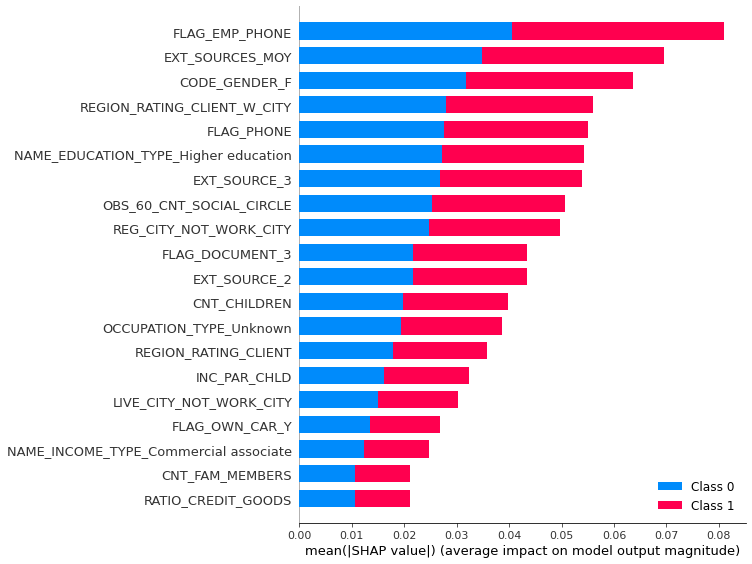

In [5]:
prediction, rf = shap_modele(X_train, y_train, X_test, modele = 'randomforest')

Dans le cas du random forest classifier, la variable qui a le plus d'impact est celle du téléphone professionnel. 
Concrètement, le fait d'avoir un travail associé à un numéro de téléphone au moment de la demande a un fort impact sur la capacité de remboursement du client. 

Ensuite, viennent des variables liées aux ressources et des variables très personnelles, voire discriminantes, comme le genre.

In [6]:
comparaison = X_test.copy(deep=True)
comparaison['PREDICTION']=prediction
comparaison[comparaison.PREDICTION == 0].head(5)

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,WALLSMATERIAL_MODE_Mixed,WALLSMATERIAL_MODE_Monolithic,WALLSMATERIAL_MODE_Others,WALLSMATERIAL_MODE_Panel,"WALLSMATERIAL_MODE_Stone, brick",WALLSMATERIAL_MODE_Unknown,WALLSMATERIAL_MODE_Wooden,EMERGENCYSTATE_MODE_No,EMERGENCYSTATE_MODE_Yes,PREDICTION
1,110728,-0.572989,0.284940,3.294398,2.938330,3.284216,-0.152365,-0.040506,0.938866,-0.166107,...,0,0,0,0,1,0,0,1,0,0
2,104508,-0.572989,-0.339792,-0.115347,-0.086290,-0.220453,-0.210596,-0.947458,0.208613,-0.336027,...,0,0,0,0,0,1,0,1,0,0
3,102377,-0.572989,-0.339792,-0.202727,-0.454145,-0.208771,0.820124,1.409124,-0.852761,1.523627,...,0,0,0,0,0,1,0,1,0,0
4,104134,-0.572989,-0.339792,-0.557790,-0.615180,-0.454097,-0.134562,1.580754,-0.852761,-0.987007,...,0,0,0,0,0,1,0,1,0,0
5,102276,-0.572989,3.985278,-0.665389,-0.773058,-0.220453,3.653471,-0.790539,0.314878,-0.450265,...,0,0,0,0,0,0,0,1,0,0


Prenons l'exemple d'un client qui celui le modèle aurait remboursé son crédit. 

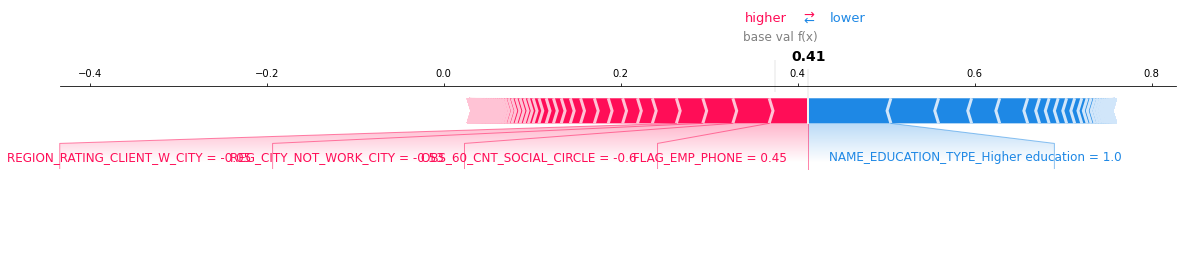

In [7]:
shap_value_modele(rf, X_test.loc[[1]], 'randomforest' , visualisation = 'force')

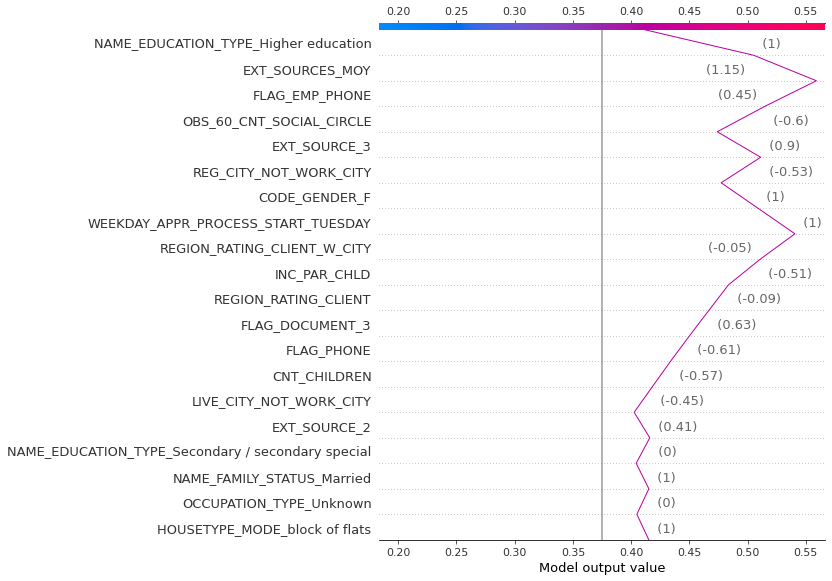

In [8]:
shap_value_modele(rf, X_test.loc[[1]], 'randomforest' , visualisation = 'decision')

Les visualisations ci-dessus représentent l'explication locale du modèle. Plus les variables font dévier le score du client vers la gauche, plus il va avoir l'étiquette '0' ("remboursé"). 

Les variables qui le font le plus dévier sont par exemple :

- CODE_GENDER_F (valeur :1, le client est une femme), 
- EXT_SOURCES_MOY (valeur : 1.15) 
- et NAME_EDUCATION_TYPE_Higher education (valeur 1).


A contratrio, les variables qui ont manqué de donner l'étiquette '1' (non-remboursé) à cette client sont 

- FLAG_EMP_PHONE
- REG_CITY_NOT_WORk_CITY
- REGION_RATING_CLIENT_W_CITY.

Regardons maintenant un client dont le modèle prédit le non-remboursement du prêt.

In [9]:
comparaison = X_test.copy(deep=True)
comparaison['PREDICTION']=prediction
comparaison[comparaison.PREDICTION == 1].head(5)

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,WALLSMATERIAL_MODE_Mixed,WALLSMATERIAL_MODE_Monolithic,WALLSMATERIAL_MODE_Others,WALLSMATERIAL_MODE_Panel,"WALLSMATERIAL_MODE_Stone, brick",WALLSMATERIAL_MODE_Unknown,WALLSMATERIAL_MODE_Wooden,EMERGENCYSTATE_MODE_No,EMERGENCYSTATE_MODE_Yes,PREDICTION
0,109351,-0.572989,-0.580074,-0.679559,-0.023771,-0.804564,0.115387,-1.564625,-0.691664,-0.891139,...,0,0,0,0,1,0,0,1,0,1
6,101476,3.466889,-0.339792,-0.202727,-0.152599,-0.208771,-0.860507,0.053365,0.104048,0.346525,...,0,0,0,0,1,0,0,1,0,1
8,104927,-0.572989,-0.435905,-0.931371,-0.913569,-0.921387,0.692029,-0.908929,-0.688688,-0.473514,...,0,0,0,0,1,0,0,1,0,1
9,100547,-0.572989,0.477165,-0.342594,-0.342368,-0.220453,0.382571,-1.392061,-0.789852,-1.204861,...,0,0,0,0,1,0,0,1,0,1
10,109220,0.773637,-1.252863,-0.880585,-1.110284,-0.804564,-0.092857,-0.261873,-0.454905,-0.515994,...,0,0,0,0,0,1,0,1,0,1


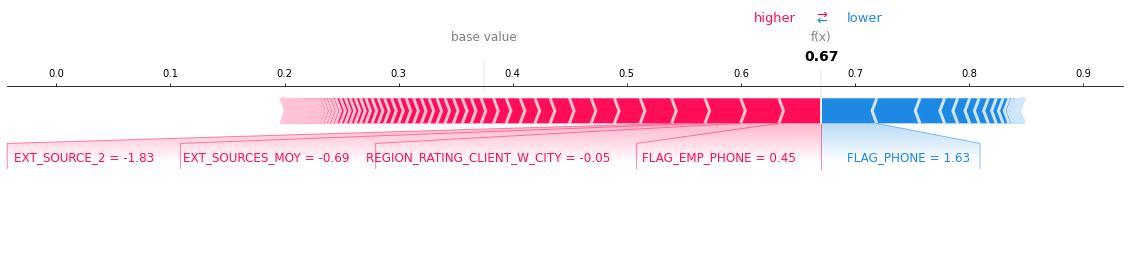

In [10]:
shap_value_modele(rf, X_test.loc[[0]],  'randomforest' , visualisation = 'force')

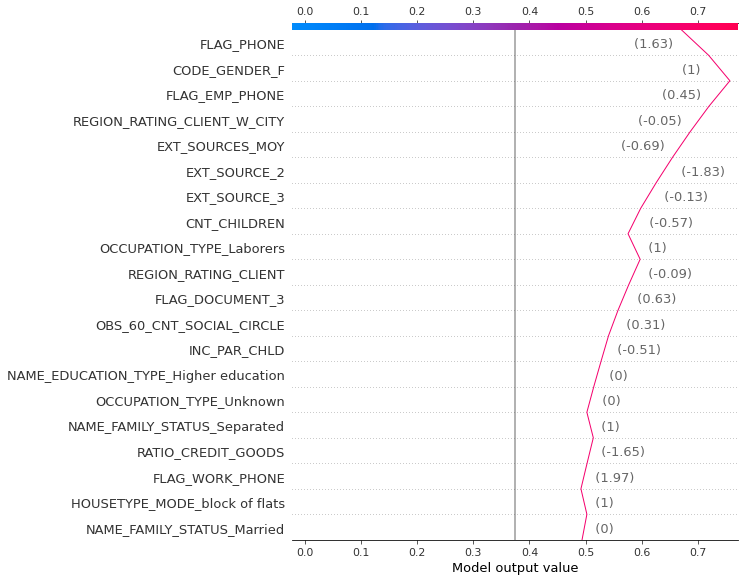

In [11]:
shap_value_modele(rf, X_test.loc[[0]],  'randomforest' , visualisation = 'decision')

Ce client a pratiquement toutes les variables présentées qui le desservent. 

Seul le fait d'être une femme et le fait d'avoir un numero de téléphone fait dévier son score vers "0". 
    
Si nous avions fait la prédiction sur le jeu de test réel, il aurait été très compliqué d'expliquer à cette cliente les raisons pour lesquelles elle n'était pas loin de voir sa demande acceptée.

## Exemple avec le modèle GBOOST

Regardons si nous pouvons avoir une meilleure interprétation avec un modèle plus performant face à notre problématique : l'algorithme GBOOST.

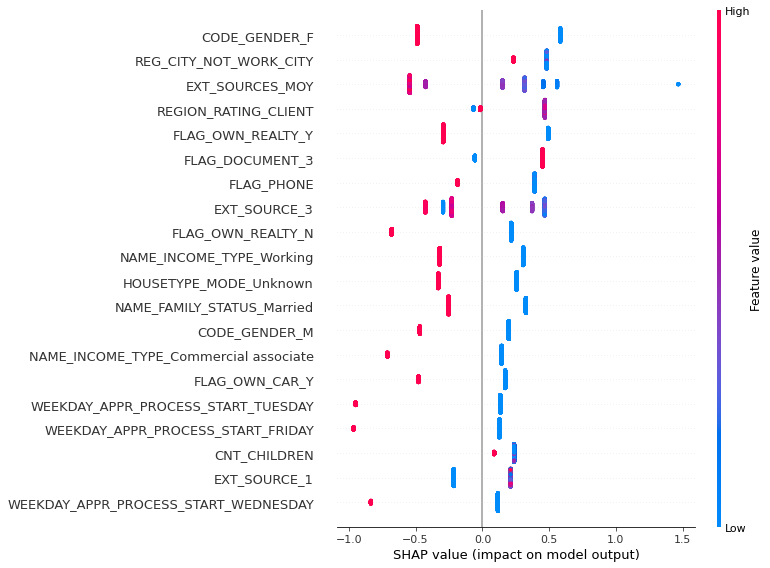

In [12]:
prediction, gb = shap_modele(X_train, y_train, X_test, modele = 'gradientboost')

Cette fois-ci, les variables déterminantes sont un peu plus précises. Il y a par exemple la variable EXT_SOURCE_3 qui est prépondérante. Déjà posséder une propriété, être marié, avoir des enfants et une voiture sont des paramètres qui influencent très fortement la prédiction.

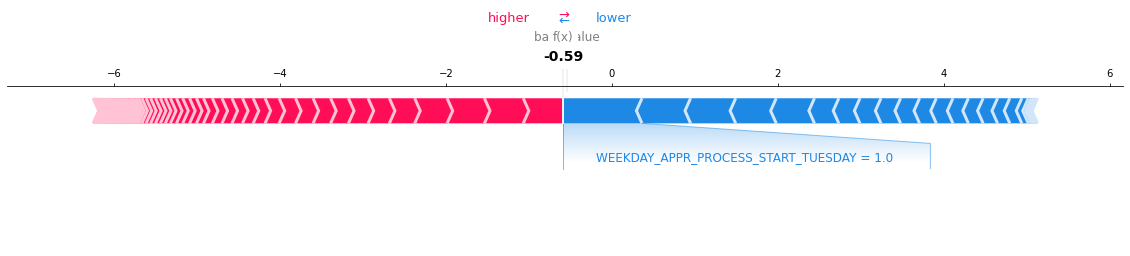

In [13]:
shap_value_modele(gb, X_test.loc[[1]],  'gradientboost', visualisation = 'force')

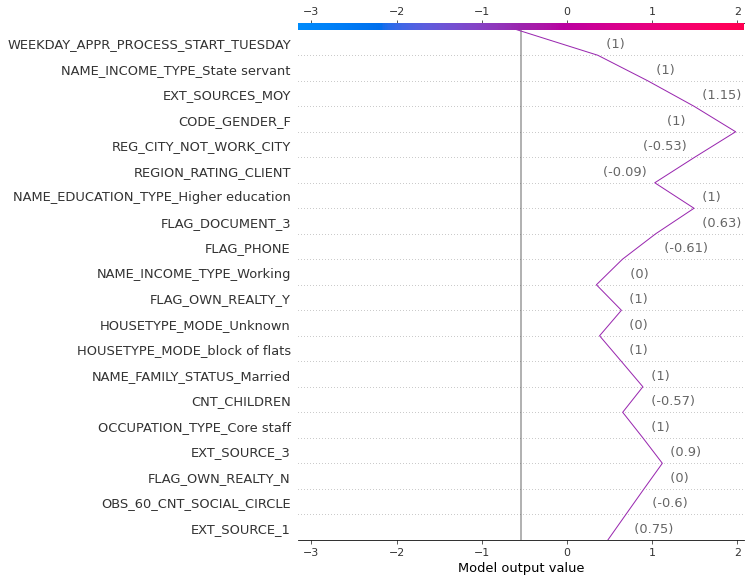

In [14]:
shap_value_modele(gb,  X_test.loc[[1]],  'gradientboost', visualisation = 'decision')

Pour ce client, le modèle prédit un remboursement du prêt. Cette fois-ci, le fait d'être un homme influence fortement la prédiction vers une étiquette 'remboursé'. Encore une fois, ce genre de variables va poser un problème étique lors de l'explication en face à face avec le client.

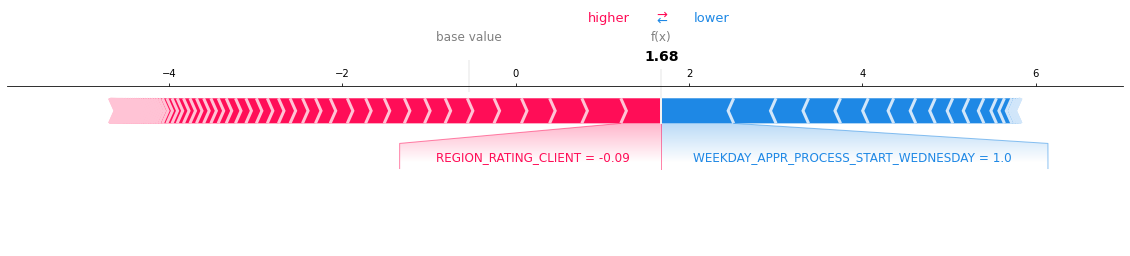

In [15]:
shap_value_modele(gb, X_test.loc[[0]],  'gradientboost', visualisation = 'force')

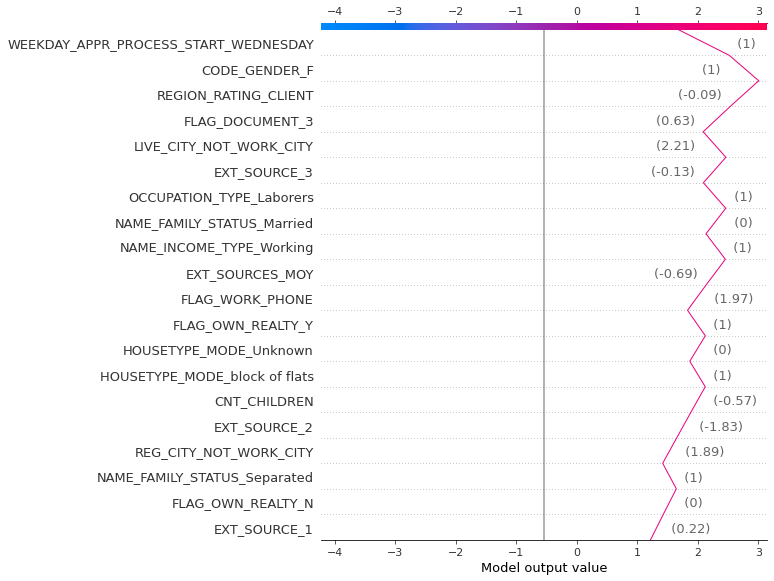

In [16]:
shap_value_modele(gb, X_test.loc[[0]],  'gradientboost', visualisation = 'decision')

## Base de données application_train pour le jeu de d'entraînement et base de données application_test pour le jeu de test

Cette fois, la prédiction se fait avec le vrai jeu de test. Les clients n'ont pas été étiquettés préalablement.

### Préparation des données

In [17]:
df_test=application_test_net_fe()

La base de données 'application_test' présente  48744 entrées pour  121 variables
L'étape de nettoyage des variables est terminée
L'étape de création de nouvelles variables est terminée.  15 nouvelles variables ont été crées


In [19]:
X_train, y_train, X_test = preparation_train_test_diff(df, df_test)

## Exemple avec le modèle random forest

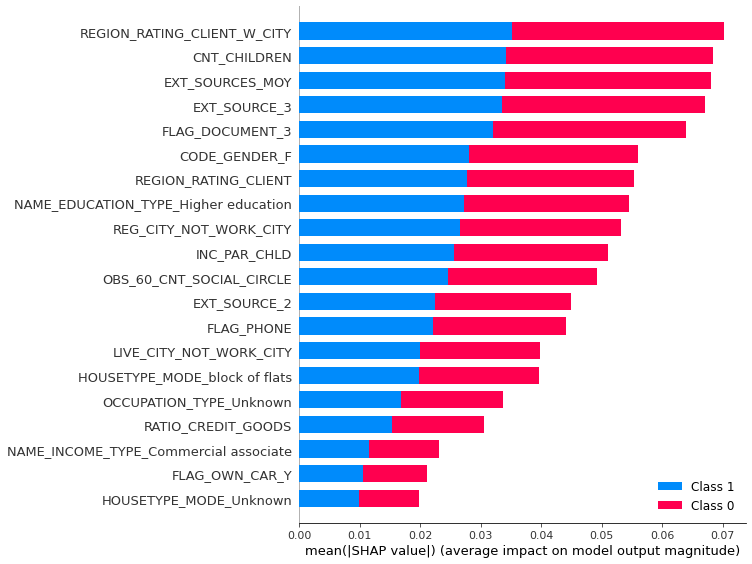

In [20]:
prediction, rf = shap_modele(X_train, y_train, X_test, modele = 'randomforest')

Regardons maintenant un client dont le modèle prédit le remboursement du prêt.

In [21]:
comparaison = X_test.copy(deep=True)
comparaison['PREDICTION']=prediction
comparaison[comparaison.PREDICTION == 0].head(5)

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,WALLSMATERIAL_MODE_Mixed,WALLSMATERIAL_MODE_Monolithic,WALLSMATERIAL_MODE_Others,WALLSMATERIAL_MODE_Panel,"WALLSMATERIAL_MODE_Stone, brick",WALLSMATERIAL_MODE_Unknown,WALLSMATERIAL_MODE_Wooden,EMERGENCYSTATE_MODE_No,EMERGENCYSTATE_MODE_Yes,PREDICTION
0,100001,-0.559988,-0.427809,0.142475,-0.553580,-0.037477,-0.164654,0.733477,0.141070,0.056958,...,0,0,0,0,1,0,0,1,0,0
2,100013,-0.559988,0.237075,0.401002,2.520066,0.497113,-0.147258,0.917718,1.069519,-0.786092,...,0,0,0,0,0,1,0,1,0,0
3,100028,2.260729,1.345214,2.896221,1.223666,3.303709,0.358078,-0.483623,-0.060843,-0.835352,...,0,0,0,1,0,0,0,1,0,0
6,100057,2.260729,0.015447,-0.047947,-0.456343,-0.264678,0.109118,0.142611,0.250530,1.451721,...,0,0,0,0,0,1,0,1,0,0
7,100065,-0.559988,-0.117530,-0.921584,-0.949554,-0.839362,-1.114610,-1.514633,-0.269733,0.026839,...,0,0,0,0,0,1,0,1,0,0


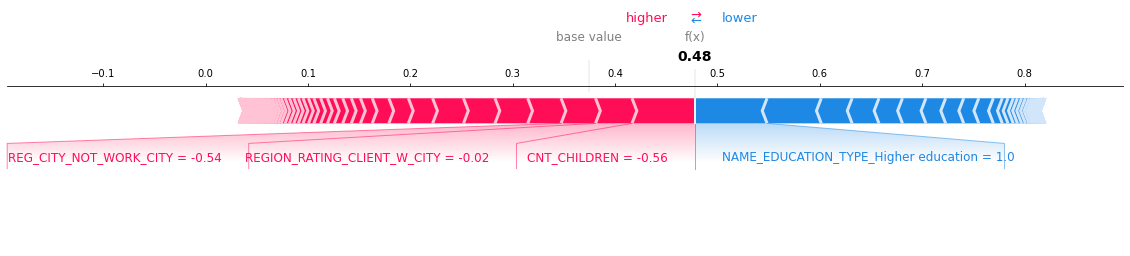

In [22]:
shap_value_modele(rf, X_test.loc[[0]],  'randomforest' ,  visualisation = 'force')

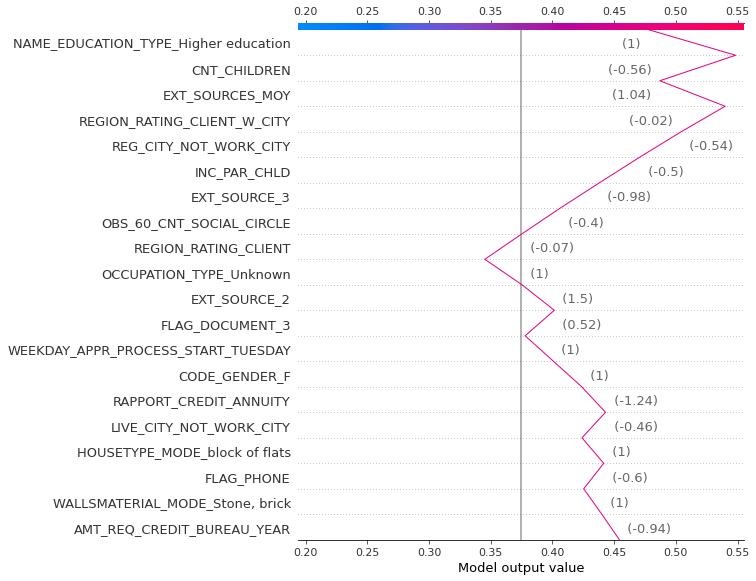

In [23]:
shap_value_modele(rf, X_test.loc[[0]],  'randomforest' ,  visualisation = 'decision')

Regardons maintenant un client dont le modèle prédit le non-remboursement du prêt.

In [24]:
comparaison = X_test.copy(deep=True)
comparaison['PREDICTION']=prediction
comparaison[comparaison.PREDICTION == 1].head(5)

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,WALLSMATERIAL_MODE_Mixed,WALLSMATERIAL_MODE_Monolithic,WALLSMATERIAL_MODE_Others,WALLSMATERIAL_MODE_Panel,"WALLSMATERIAL_MODE_Stone, brick",WALLSMATERIAL_MODE_Unknown,WALLSMATERIAL_MODE_Wooden,EMERGENCYSTATE_MODE_No,EMERGENCYSTATE_MODE_Yes,PREDICTION
1,100005,-0.559988,-0.782413,-0.804537,-0.752831,-0.839362,1.009586,0.461392,1.074316,1.168264,...,0,0,0,0,0,1,0,1,0,1
4,100038,0.850370,0.015447,0.297651,0.165019,0.483748,-0.775825,-0.699997,0.080889,-0.272381,...,0,0,0,0,0,1,0,1,0,1
5,100042,-0.559988,0.901958,1.212249,0.323240,1.031702,0.272965,0.586223,4.362481,0.323244,...,0,0,0,0,0,0,0,1,0,1
9,100067,0.850370,-0.161855,-1.291049,-1.504310,-1.240304,-0.179625,-1.311436,0.270154,0.888467,...,0,0,0,0,0,1,0,1,0,1
11,100090,-0.559988,-0.427809,-0.698205,-0.785431,-0.732444,-0.915345,-0.125775,0.675724,0.806555,...,0,0,0,0,0,1,0,1,0,1


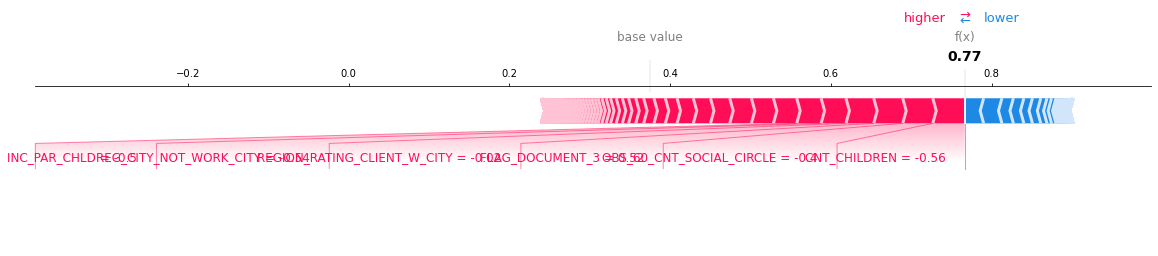

In [25]:
shap_value_modele(rf, X_test.loc[[1]],  'randomforest' ,  visualisation = 'force')

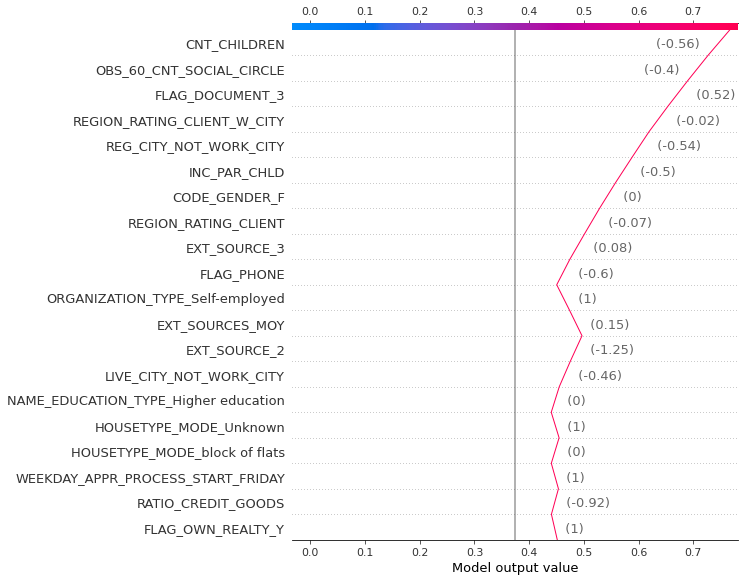

In [26]:
shap_value_modele(rf, X_test.loc[[1]],  'randomforest' ,  visualisation = 'decision')

## Exemple avec le modèle GBOOST

Regardons si nous pouvons avoir une meilleure interprétation avec un modèle plus performant face à notre problématique : l'algorithme GBOOST.

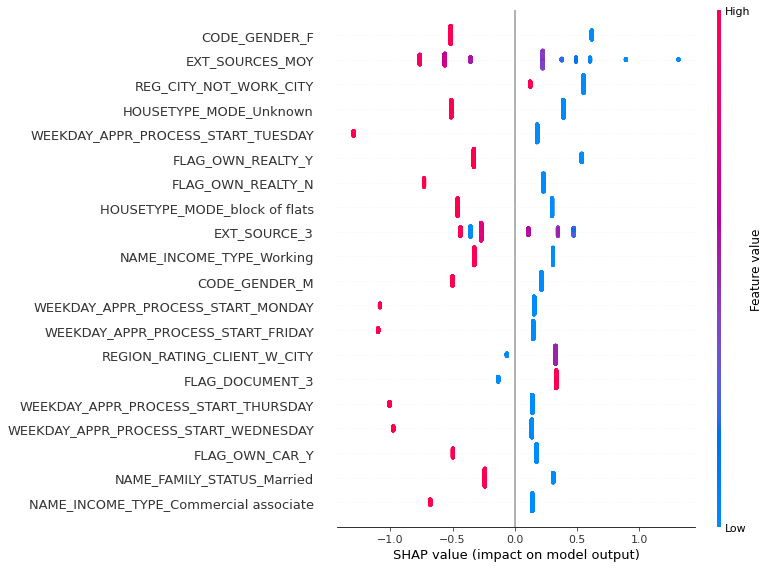

In [27]:
prediction, gb = shap_modele(X_train, y_train, X_test, modele = 'gradientboost')

Cette fois-ci, les variables déterminantes sont un peu plus précises. Il y a par exemple la variable EXT_SOURCE_3 qui est prépondérante. Déjà posséder une propriété, être marié, avoir des enfants et une voiture sont des paramètres qui influencent très fortement la prédiction.

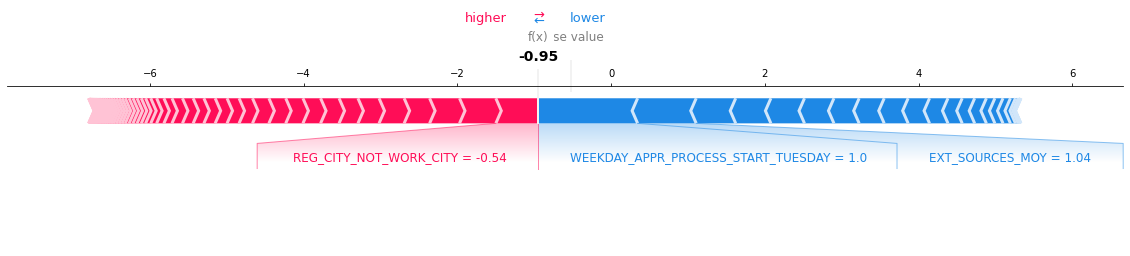

In [28]:
shap_value_modele(gb, X_test.loc[[0]],  'gradientboost', visualisation = 'force')

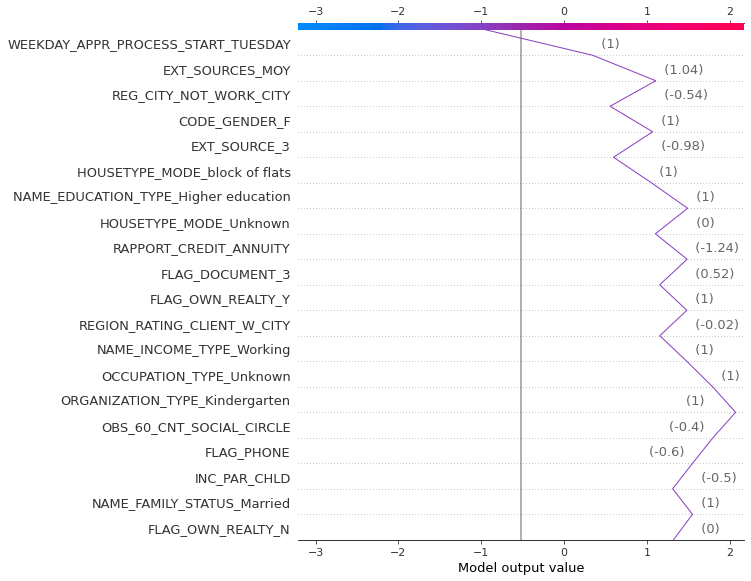

In [29]:
shap_value_modele(gb, X_test.loc[[0]],  'gradientboost', visualisation = 'decision')

Pour ce client, le modèle prédit un remboursement du prêt. Cette fois-ci, le fait d'être un homme influence fortement la prédiction vers une étiquette 'remboursé'. Encore une fois, ce genre de variables va poser un problème étique lors de l'explication en face à face avec le client.

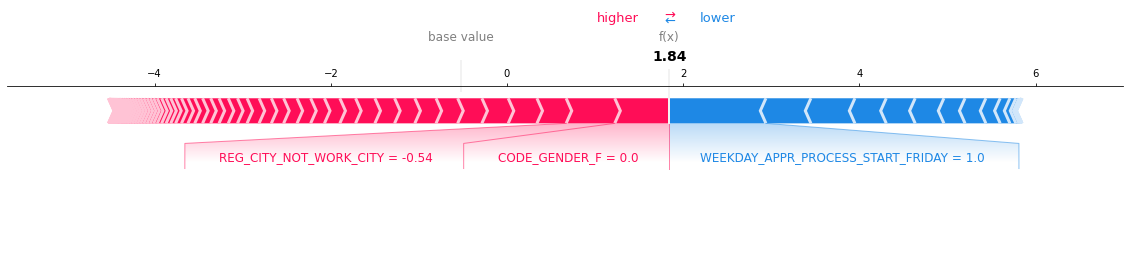

In [30]:
shap_value_modele(gb, X_test.loc[[1]],  'gradientboost', visualisation = 'force')

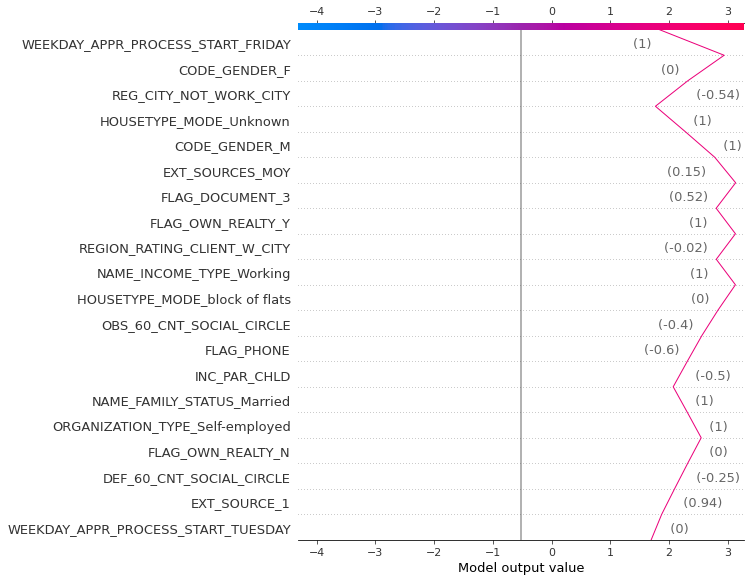

In [31]:
shap_value_modele(gb, X_test.loc[[1]],  'gradientboost', visualisation = 'decision')

Le modèle GBOOST est beaucoup plus interprétable.

# Conclusion

Ce projet a présenté différents aspects de la démarche de la construction d'un modèle et de son interprétation.
D'abord, les données ont été nettoyées, visualisées et explorées.
Ensuite, de nouvelles variables ont été créées. Ces variables ont permis d'obtenir une performance du modèle accrue de presque 20% par rapport à un modèle construit sans les nouvelles variables.

La performance des différents modèles a été évaluée grâce à plusieurs critères. D'abord des critères purement statistiques, avec des mesures de précision, de sensibilité et des matrices de confusion. Néanmoins, bien que très importants, ces critères ne permettent pas de totalement discriminer un modèle d'un autre. Pour ce faire, de nouveaux indicateurs ont été créés, plus en adéquation avec la problématique financière du projet. D'abord, un bénéfice supplémentaire induit par l'utilisation du modèle a été calculé, puis un bénéfice supplémentaire par demande et un bénéfice supplémentaire par dollar investi ont été déterminés. Aussi, le temps de calcul est un critère de choix. En effet, plus le calcul prend du temps, plus il est coûteux financièrement.

Plusieurs types de modèles ont été testés. Ils ont été de différents types. Le modèle de régression logistique est celui qui a eu les meilleures performances parmi les modèles linéaires. L'algorithme de l'arbre de décision a été le plus performant de tous. Enfin, des modèles ensemblistes ont été essayé et plusieurs ont donné de très bons résultats.

Pour aller plus loin, un modèle de Deep Learning, reposant sur le principe de réseaux de neurones (MLP) a aussi permis de faire des prédictions. Néanmoins, il n'a pas été beaucoup plus performant que d'autres modèles.


L'interprétation du modèle se fait de deux façons. D'abord, globalement, l'importance des variables est déterminée à l'échelle du modèle, de la base de données. Ensuite, la prédiction est expliquée localement, pour chaque client.
Ceci est très important pour trois raisons. D'abord légalement, la loi prévoit que personne ne doit subir la décision d'une machine uniquement. Ensuite, la personne demandant un crédit doit pouvoir voir son refus être expliqué par la banque. Enfin, pour le créateur du modèle, il est primordial de vérifier la cohérence du modèle avec la réalité de la situation.

Les interprétations des modèles de ce projet sont techniquement très valables et plutôt cohérentes. Néanmoins, elles posent énormément de problèmes. En effet, les variables qui ont de l'importance sont celles qui concernent les ressources externes. Jusqu'ici, rien de très discriminant. Mais quand on regarde les variables qui ont une importance légèrement inférieure, on retrouve des données très personnelles, et notamment le genre ou le statut marital. Comment peut-on expliquer à un client qu'il ne peut pas avoir son prêt car il est un homme non-marié comme pourrait le faire comprendre l'algorithme. 
De plus, comment justifier l'utilisation de telles données, privées voire intimes, même si elles permettent d'augmenter considérablement la performance des modèles.

Ces considérations posent les bases d'une réflexion sur les aspects éthiques et juridiques du recueil de données privées et de leur utilisation. 

# Sources et inspirations

**Importance des variables / Interprétabilité**

https://blog.octo.com/introduction-a-linterpretation-de-modeles-de-machine-learning/

https://www.aquiladata.fr/insights/interpretabilite-des-modeles-de-machine-learning/

https://machinelearningmastery.com/calculate-feature-importance-with-python/

https://medium.com/@tonyxu_71807/ensuring-fairness-and-explainability-in-credit-default-risk-modeling-shap-ibm-tool-kit-aix-360-bfc519c191bf

    
**SHAP - valeurs de Shapley (et LIME)**

https://colab.research.google.com/drive/1pjPzsw_uZew-Zcz646JTkRDhF2GkPk0N

https://coderzcolumn.com/tutorials/machine-learning/shap-explain-machine-learning-model-predictions-using-game-theoretic-approach

https://www.aquiladata.fr/insights/shap-mieux-comprendre-linterpretation-de-modeles/

https://www.kaggle.com/code/wrosinski/shap-feature-importance-with-feature-engineering/notebook

https://www.kaggle.com/code/vikumsw/explaining-random-forest-model-with-shapely-values/notebook
